In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
df = pd.read_csv('/boston_housing_data.csv')

In [ ]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [ ]:
df.isnull().any()

,0
CRIM,True
ZN,True
INDUS,True
CHAS,True
NOX,False
RM,False
AGE,True
DIS,False
RAD,False
TAX,False


In [ ]:
df = df.fillna(df.mean())
df.isnull().any()

,0
CRIM,False
ZN,False
INDUS,False
CHAS,False
NOX,False
RM,False
AGE,False
DIS,False
RAD,False
TAX,False


In [ ]:
x = df.drop('MEDV', axis=1)
y = df['MEDV']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
model = Sequential()
model.add(Dense(64, input_dim = x_train.shape[1], activation='relu'))  # input_dim sets the no. of input features (columns)
model.add(Dense(32, activation='relu'))
model.add(Dense(1))

In [ ]:
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    x_train, y_train,
    epochs = 300,
    batch_size =  16,
    validation_split = 0.1,
    verbose = 1)

Epoch 1/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 559.1462 - mae: 21.5945 - val_loss: 511.6318 - val_mae: 20.8958
Epoch 2/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 502.4838 - mae: 20.3831 - val_loss: 405.3123 - val_mae: 18.2508
Epoch 3/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 374.5003 - mae: 16.7829 - val_loss: 260.4366 - val_mae: 14.2822
Epoch 4/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 228.6783 - mae: 12.7746 - val_loss: 119.6596 - val_mae: 9.0411
Epoch 5/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 104.3001 - mae: 8.3839 - val_loss: 57.4633 - val_mae: 5.3707
Epoch 6/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 62.5569 - mae: 6.2886 - val_loss: 40.4774 - val_mae: 4.1809
Epoch 7/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 47.7426 - mae: 5.2871 - val_loss: 35.8693 - val_mae: 3.7796
Epoch 8/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 30.3496 - mae: 4.1193 - val_loss: 35.2287 - val_mae: 3.7930
Epoch 9/300
23/23 ━━━━━━━━━━━━━

In [ ]:
test_mse, test_mae = model.evaluate(x_test, y_test, verbose=1)
rmse = np.sqrt(test_mse)
print('MSE on test data: ', rmse)
print('MSE on test data: ', test_mse)
print('MAE on test data: ', test_mae)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 10.7007 - mae: 2.2648
MSE on test data:  3.7166977035754716
MSE on test data:  13.813841819763184
MAE on test data:  2.4388439655303955


In [ ]:
# make predictions
y_pred = model.predict(x_test)

# compare first few predictions with actual values
print('\nPredicted vs. Actual')
for i in range(5):
    print('Predicted: ', y_pred[i][0], '| Actual: ', y_test.iloc[i])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

Predicted vs. Actual
Predicted:  27.764954 | Actual:  23.6
Predicted:  34.97004 | Actual:  32.4
Predicted:  15.152005 | Actual:  13.6
Predicted:  24.842583 | Actual:  22.8
Predicted:  13.922635 | Actual:  16.1


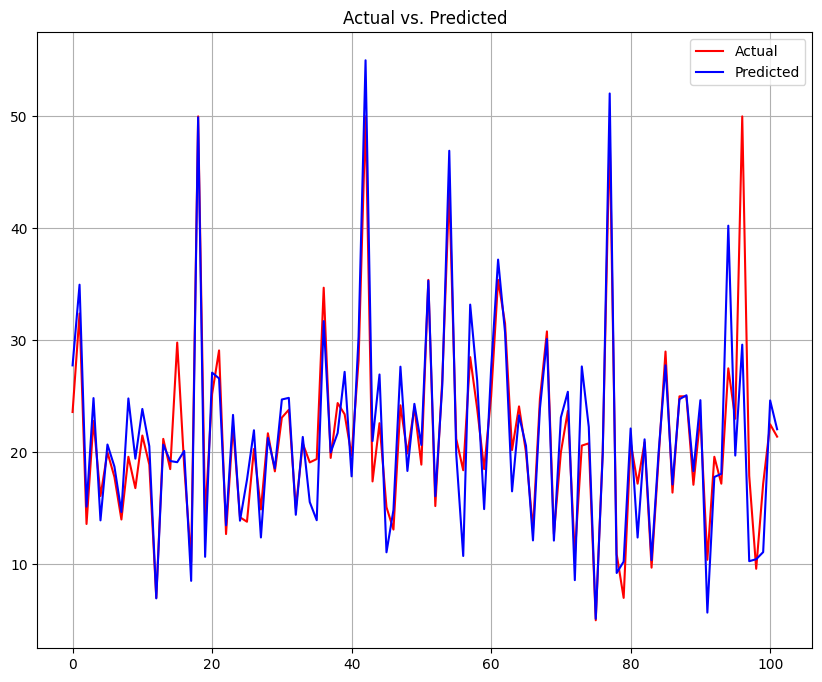

In [ ]:
import matplotlib.pyplot as plt

# reshape to 2D array
y_test = np.array(y_test).reshape(-1, 1)

plt.figure(figsize=(10, 8))
plt.plot(y_test, label='Actual', color='red')
plt.plot(y_pred, label='Predicted', color='blue')
plt.title('Actual vs. Predicted')
plt.legend()
plt.grid(True)
plt.show()